# Customer Churn Analysis

**Goal:** Analyse telecom customer behaviour data to identify the factors that most influence customer churn, and translate the findings into concrete retention strategies.

**Dataset:** IBM/Kaggle *Telco Customer Churn* (7,043 customers, 21 attributes)

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, SciPy

**Sections**
1. Data Loading & Cleaning
2. Feature Engineering
3. Exploratory Data Analysis (Demographics, Tenure, Service Usage)
4. Key Drivers of Churn
5. Retention Strategy Recommendations


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

df = pd.read_csv("../data/telecom_customer_churn.csv")
print(df.shape)
df.head()


(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Data Cleaning

Check for missing values, duplicate records, and inconsistent types before doing any analysis.

In [2]:
# Missing values
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])

# Duplicate customer records
print("\nDuplicate rows:", df.duplicated(subset="customerID").sum())


Missing values per column:
Series([], dtype: int64)

Duplicate rows: 0


In [3]:
# Drop exact duplicate customer records
df = df.drop_duplicates(subset="customerID").reset_index(drop=True)

# TotalCharges is stored as text in the raw file (11 blank strings, all brand-new customers
# with tenure 0). Coerce to numeric, then impute with tenure * MonthlyCharges (= 0 for them).
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
missing_mask = df["TotalCharges"].isna()
df.loc[missing_mask, "TotalCharges"] = (
    df.loc[missing_mask, "tenure"] * df.loc[missing_mask, "MonthlyCharges"]
)

# Standardise categorical text and binary flags
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
df["SeniorCitizen"] = df["SeniorCitizen"].map({1: "Yes", 0: "No"})

print("Remaining nulls:", df.isna().sum().sum())
df.info()


Remaining nulls: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   object 
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 

## 2. Feature Engineering

Derive features that make churn patterns easier to see: tenure buckets, a simple service-adoption count, and average revenue per month of tenure.

In [4]:
# Tenure buckets
bins = [0, 12, 24, 48, 72]
labels = ["0-12 mo", "13-24 mo", "25-48 mo", "49-72 mo"]
df["TenureGroup"] = pd.cut(df["tenure"], bins=bins, labels=labels, include_lowest=True)

# Count of add-on services actively used (proxy for engagement/stickiness)
service_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                 "TechSupport", "StreamingTV", "StreamingMovies"]
df["NumServices"] = (df[service_cols] == "Yes").sum(axis=1)

# Charges per month of tenure (flags customers paying a lot relative to how new they are)
df["AvgMonthlySpend"] = df["TotalCharges"] / df["tenure"].replace(0, 1)

df[["tenure", "TenureGroup", "NumServices", "AvgMonthlySpend"]].head()


,tenure,TenureGroup,NumServices,AvgMonthlySpend
0,1,0-12 mo,1,29.850000
1,34,25-48 mo,2,55.573529
2,2,0-12 mo,2,54.075000
3,45,25-48 mo,3,40.905556
4,2,0-12 mo,0,75.825000


## 3. Exploratory Analysis

### 3.1 Overall churn rate

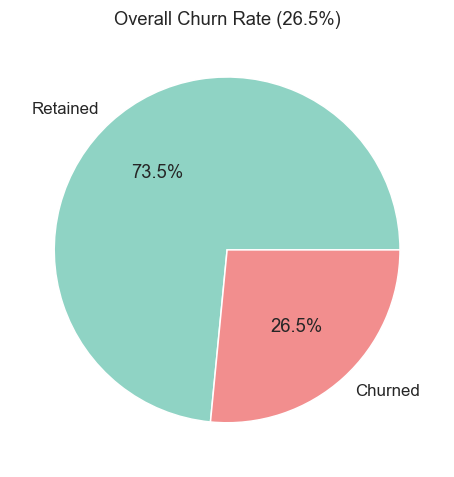

In [5]:
churn_rate = df["Churn"].mean()
fig, ax = plt.subplots(figsize=(4.5, 4.5))
df["Churn"].map({1: "Churned", 0: "Retained"}).value_counts().plot(
    kind="pie", autopct="%1.1f%%", colors=["#8fd3c4", "#f28e8e"], ax=ax, ylabel=""
)
ax.set_title(f"Overall Churn Rate ({churn_rate:.1%})")
plt.tight_layout()
plt.savefig("../images/01_overall_churn_rate.png")
plt.show()


### 3.2 Churn by demographics (gender, senior citizen, dependents, partner)

C:\Users\Prerana Hembrom\AppData\Local\Temp\ipykernel_2336\904560158.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rates.index, y=rates.values, ax=ax, palette="Set2")
C:\Users\Prerana Hembrom\AppData\Local\Temp\ipykernel_2336\904560158.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rates.index, y=rates.values, ax=ax, palette="Set2")
C:\Users\Prerana Hembrom\AppData\Local\Temp\ipykernel_2336\904560158.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rates.index, y=rates.values, ax=ax, palette="Set2")
C:\Users\Prerana Hembr

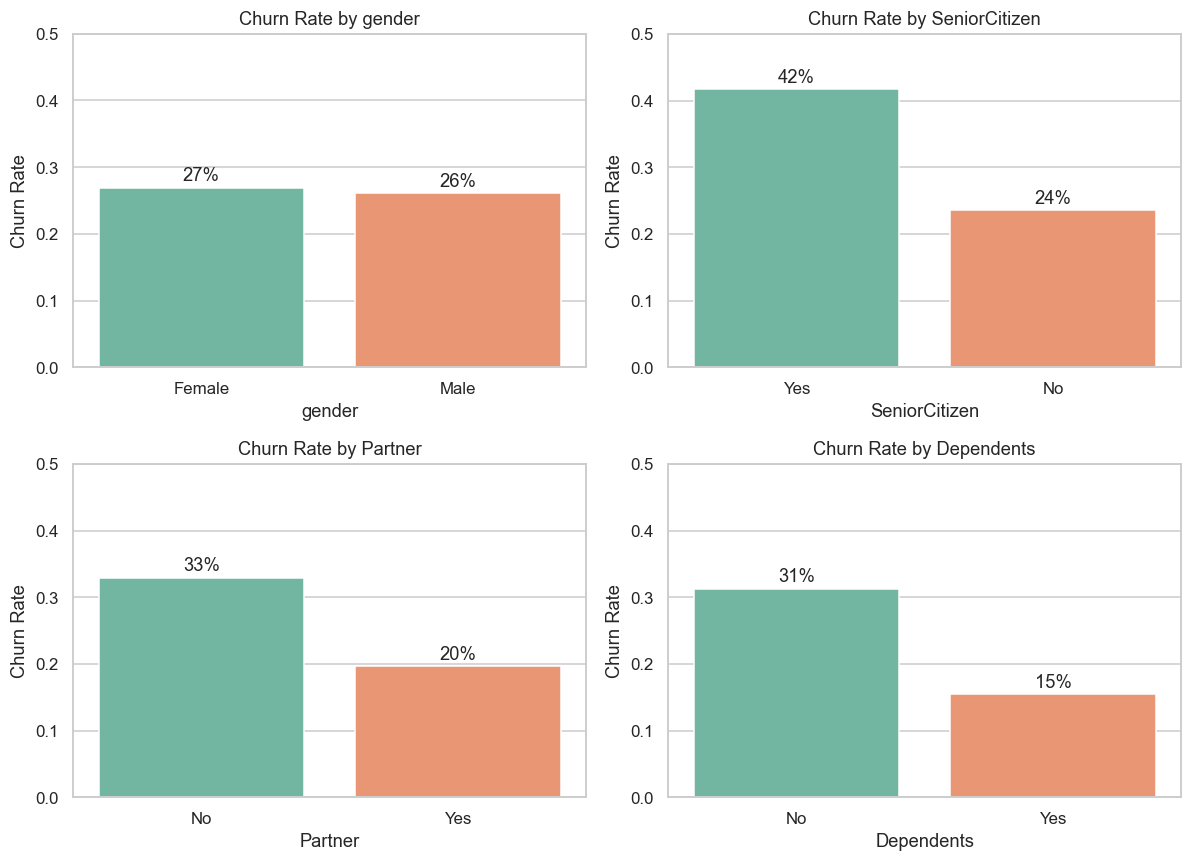

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
demo_cols = ["gender", "SeniorCitizen", "Partner", "Dependents"]
for ax, col in zip(axes.flat, demo_cols):
    rates = df.groupby(col)["Churn"].mean().sort_values(ascending=False)
    sns.barplot(x=rates.index, y=rates.values, ax=ax, palette="Set2")
    ax.set_title(f"Churn Rate by {col}")
    ax.set_ylabel("Churn Rate")
    ax.set_ylim(0, max(0.5, rates.max() * 1.2))
    for i, v in enumerate(rates.values):
        ax.text(i, v + 0.01, f"{v:.0%}", ha="center")
plt.tight_layout()
plt.savefig("../images/02_churn_by_demographics.png")
plt.show()


**Observation:** Gender makes no real difference (~27% vs ~26%). Demographics that matter: senior citizens churn at ~42% vs ~24% for non-seniors, while customers with a partner (~20% vs ~33%) or dependents (~16% vs ~31%) churn far less — single-person accounts are the easiest to walk away.

### 3.3 Churn by tenure

C:\Users\Prerana Hembrom\AppData\Local\Temp\ipykernel_2336\4084884720.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=tenure_rates.index, y=tenure_rates.values, ax=axes[1], palette="Set2")


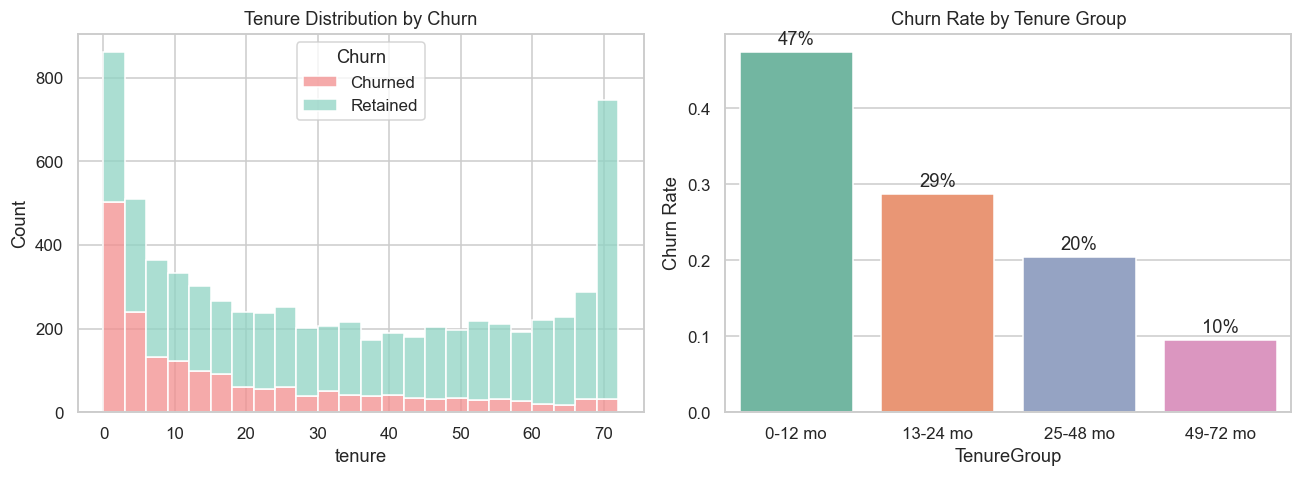

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(data=df, x="tenure", hue="Churn", multiple="stack",
             palette={0: "#8fd3c4", 1: "#f28e8e"}, ax=axes[0], bins=24)
axes[0].set_title("Tenure Distribution by Churn")
axes[0].legend(title="Churn", labels=["Churned", "Retained"])

tenure_rates = df.groupby("TenureGroup", observed=True)["Churn"].mean()
sns.barplot(x=tenure_rates.index, y=tenure_rates.values, ax=axes[1], palette="Set2")
axes[1].set_title("Churn Rate by Tenure Group")
axes[1].set_ylabel("Churn Rate")
for i, v in enumerate(tenure_rates.values):
    axes[1].text(i, v + 0.01, f"{v:.0%}", ha="center")

plt.tight_layout()
plt.savefig("../images/03_churn_by_tenure.png")
plt.show()


**Observation:** Churn is heavily front-loaded — roughly 47% of customers in their first 12 months churn, falling to ~29%, ~20% and ~10% in later tenure bands. New customers are by far the highest-risk group.

### 3.4 Churn by contract type and payment method

C:\Users\Prerana Hembrom\AppData\Local\Temp\ipykernel_2336\1784918602.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=contract_rates.index, y=contract_rates.values, ax=axes[0], palette="Set2")
C:\Users\Prerana Hembrom\AppData\Local\Temp\ipykernel_2336\1784918602.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=pay_rates.index, x=pay_rates.values, ax=axes[1], palette="Set2", orient="h")


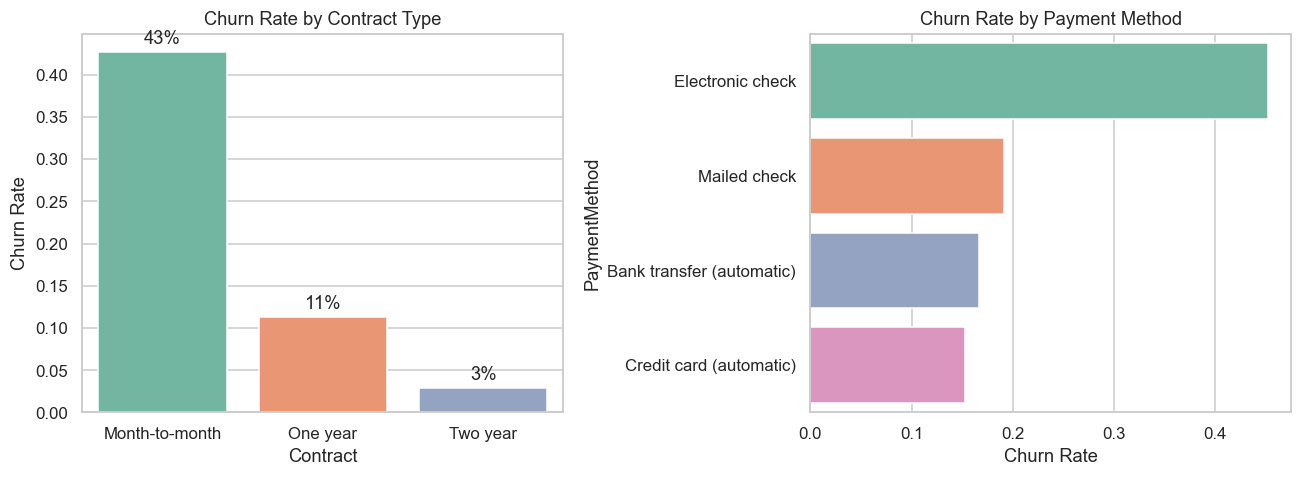

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

contract_rates = df.groupby("Contract")["Churn"].mean().sort_values(ascending=False)
sns.barplot(x=contract_rates.index, y=contract_rates.values, ax=axes[0], palette="Set2")
axes[0].set_title("Churn Rate by Contract Type")
axes[0].set_ylabel("Churn Rate")
for i, v in enumerate(contract_rates.values):
    axes[0].text(i, v + 0.01, f"{v:.0%}", ha="center")

pay_rates = df.groupby("PaymentMethod")["Churn"].mean().sort_values(ascending=False)
sns.barplot(y=pay_rates.index, x=pay_rates.values, ax=axes[1], palette="Set2", orient="h")
axes[1].set_title("Churn Rate by Payment Method")
axes[1].set_xlabel("Churn Rate")

plt.tight_layout()
plt.savefig("../images/04_churn_by_contract_payment.png")
plt.show()


**Observation:** Month-to-month contracts churn at ~43% vs ~11% (one-year) and ~3% (two-year). Electronic-check payers churn at ~45%, versus ~15–19% for every other payment method — manual payment correlates strongly with flight risk.

### Statistical check: is the contract effect real?

A chi-square test of independence on Contract × Churn confirms the gap is not sampling noise.

In [9]:
from scipy.stats import chi2_contingency

for col in ["Contract", "PaymentMethod", "InternetService", "PaperlessBilling"]:
    table = pd.crosstab(df[col], df["Churn"])
    chi2, p, dof, _ = chi2_contingency(table)
    print(f"{col:18s} chi2 = {chi2:8.1f}   dof = {dof}   p-value = {p:.2e}")


Contract           chi2 =   1184.6   dof = 2   p-value = 5.86e-258
PaymentMethod      chi2 =    648.1   dof = 3   p-value = 3.68e-140
InternetService    chi2 =    732.3   dof = 2   p-value = 9.57e-160
PaperlessBilling   chi2 =    258.3   dof = 1   p-value = 4.07e-58


### 3.5 Churn by service usage (internet type, add-on services)

C:\Users\Prerana Hembrom\AppData\Local\Temp\ipykernel_2336\2920074043.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=net_rates.index, y=net_rates.values, ax=axes[0], palette="Set2")


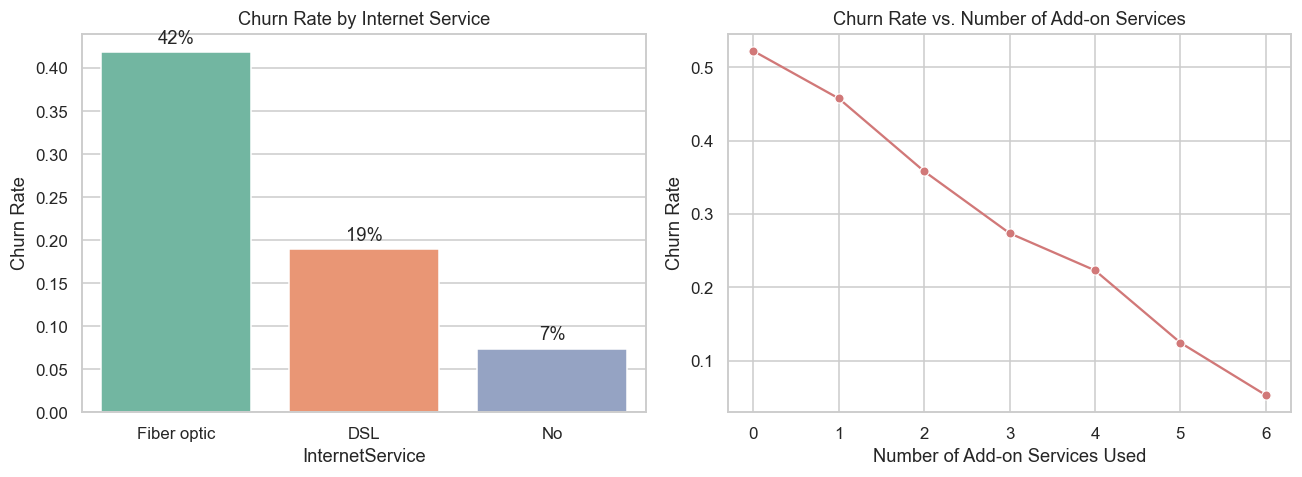

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

net_rates = df.groupby("InternetService")["Churn"].mean().sort_values(ascending=False)
sns.barplot(x=net_rates.index, y=net_rates.values, ax=axes[0], palette="Set2")
axes[0].set_title("Churn Rate by Internet Service")
axes[0].set_ylabel("Churn Rate")
for i, v in enumerate(net_rates.values):
    axes[0].text(i, v + 0.01, f"{v:.0%}", ha="center")

# Only internet customers can buy add-ons, so exclude "No internet" from this curve
svc_rates = df[df["InternetService"] != "No"].groupby("NumServices")["Churn"].mean()
sns.lineplot(x=svc_rates.index, y=svc_rates.values, marker="o", ax=axes[1], color="#d17878")
axes[1].set_title("Churn Rate vs. Number of Add-on Services")
axes[1].set_xlabel("Number of Add-on Services Used")
axes[1].set_ylabel("Churn Rate")

plt.tight_layout()
plt.savefig("../images/05_churn_by_service_usage.png")
plt.show()


**Observation:** Fiber optic customers churn at ~42% vs ~19% for DSL and ~7% for customers with no internet. Among internet customers, churn falls steadily as add-on adoption rises — from ~52% with no add-ons to ~5% with all six — so a more tied-in customer is a stickier customer.

### 3.6 Monthly charges and total spend vs churn

C:\Users\Prerana Hembrom\AppData\Local\Temp\ipykernel_2336\3144941391.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(["Retained", "Churned"])
C:\Users\Prerana Hembrom\AppData\Local\Temp\ipykernel_2336\3144941391.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(["Retained", "Churned"])


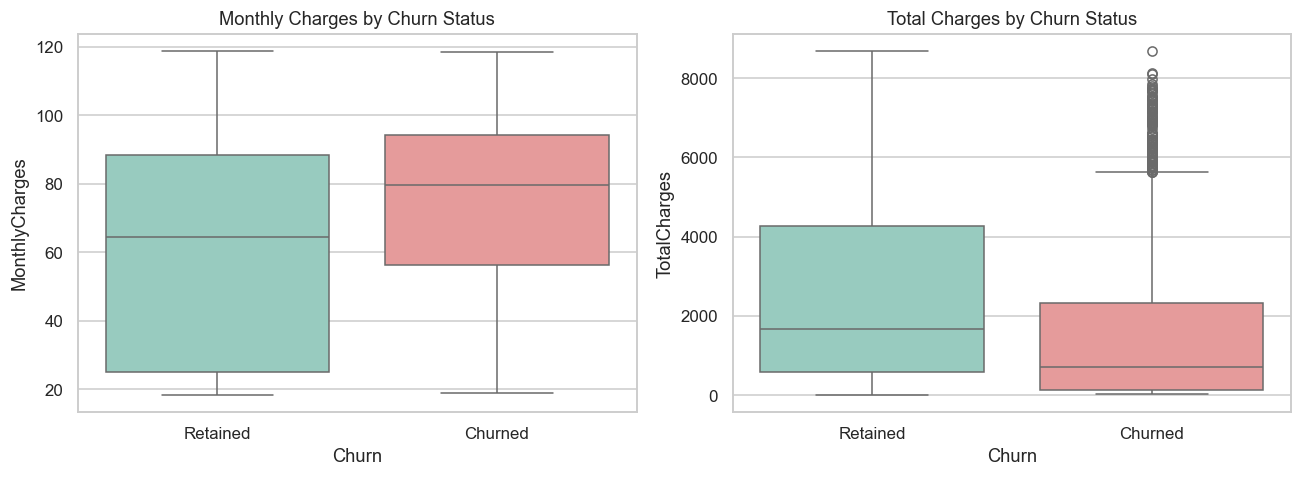

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[0], hue="Churn",
            palette={0: "#8fd3c4", 1: "#f28e8e"}, legend=False)
axes[0].set_xticklabels(["Retained", "Churned"])
axes[0].set_title("Monthly Charges by Churn Status")

sns.boxplot(data=df, x="Churn", y="TotalCharges", ax=axes[1], hue="Churn",
            palette={0: "#8fd3c4", 1: "#f28e8e"}, legend=False)
axes[1].set_xticklabels(["Retained", "Churned"])
axes[1].set_title("Total Charges by Churn Status")

plt.tight_layout()
plt.savefig("../images/06_charges_vs_churn.png")
plt.show()


### 3.7 Correlation snapshot of numeric features

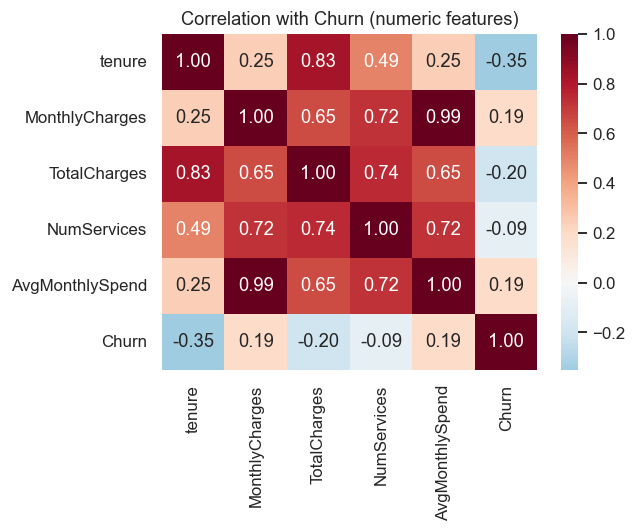

In [12]:
numeric_df = df[["tenure", "MonthlyCharges", "TotalCharges", "NumServices", "AvgMonthlySpend", "Churn"]]
corr = numeric_df.corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Correlation with Churn (numeric features)")
plt.tight_layout()
plt.savefig("../images/07_correlation_heatmap.png")
plt.show()


## 4. Key Drivers of Churn (Summary)

On the Kaggle Telco data (overall churn ≈ 26.5%), the strongest drivers are:

1. **Contract type** — month-to-month ~43% vs one-year ~11% vs two-year ~3%.
2. **Tenure** — ~47% churn in the first 12 months, falling to ~10% after 4 years.
3. **Payment method** — electronic check ~45% vs ~15–19% for all other methods.
4. **Internet service type** — fiber optic ~42% vs DSL ~19%, despite fiber being the priciest plan.
5. **Add-on adoption** — among internet customers, churn drops from ~52% (no add-ons) to ~5% (all six).
6. **Demographics** — seniors (~42%) and customers without a partner/dependents churn more; gender has no effect.

Churners also pay more per month (median ~$80 vs ~$64) and have a much shorter median tenure (10 vs 38 months).


## 5. Retention Strategy Recommendations

- **Incentivise longer contracts:** offer a meaningful discount or perk for switching month-to-month customers to 1-year plans, since contract length is the single biggest churn differentiator.
- **Protect the first 90–365 days:** build an onboarding/check-in program (welcome calls, usage tips, an early-tenure loyalty offer) targeted at customers in their first year, where churn risk is highest.
- **Push automatic payment adoption:** offer a small bill credit for switching from electronic check to autopay (bank transfer/credit card), which correlates with much lower churn.
- **Investigate fiber optic experience:** since fiber customers pay the most yet churn the most, review pricing perception and service reliability for this segment specifically — it may be an expectations/value gap rather than a price problem alone.
- **Bundle add-on services:** proactively offer free trials of security/tech-support/backup add-ons to new or at-risk customers; higher service adoption is strongly associated with retention.
- **Target senior and single-account customers:** design retention outreach (simplified plans, dedicated support) for senior citizens and customers without a partner/dependents on the account, who show elevated churn.
